In [1]:
from google.colab import files
uploaded=files.upload()

Saving online_retail_II.xlsx to online_retail_II.xlsx


In [2]:

import pandas as pd

file_name = "online_retail_II.xlsx"

# Read both sheets
df_2009 = pd.read_excel(
    file_name,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    file_name,
    sheet_name="Year 2010-2011"
)

# Combine both sheets
df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

# Display dataset information
print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())


Dataset loaded successfully!
Total Rows: 1067371
Total Columns: 8

Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Missing values:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Duplicate rows: 34335

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object


In [4]:

# Create a copy of the combined dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Remove records without Customer ID
df_clean = df_clean.dropna(subset=["Customer ID"])

# Remove cancelled invoices
df_clean = df_clean[
    ~df_clean["Invoice"].astype(str).str.startswith("C")
].copy()

# Keep only positive quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

# Convert InvoiceDate into datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Remove rows with invalid dates
df_clean = df_clean.dropna(subset=["InvoiceDate"])

# Calculate total revenue per transaction line
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["Price"]
)

# Display results
print("Original dataset rows:", len(df))
print("Cleaned dataset rows:", len(df_clean))
print("Remaining missing values:")
print(df_clean.isnull().sum())

display(df_clean.head())


Original dataset rows: 1067371
Cleaned dataset rows: 779425
Remaining missing values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
Revenue        0
dtype: int64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [5]:

# Create customer-level summary
customer_data = df_clean.groupby("Customer ID").agg(
    Total_Revenue=("Revenue", "sum"),
    Total_Orders=("Invoice", "nunique"),
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max")
).reset_index()

# Calculate average order value
customer_data["Average_Order_Value"] = (
    customer_data["Total_Revenue"] /
    customer_data["Total_Orders"]
)

# Calculate observed customer activity period
customer_data["Customer_Lifespan_Days"] = (
    customer_data["Last_Purchase"] -
    customer_data["First_Purchase"]
).dt.days

print("Total customers:", len(customer_data))
display(customer_data.head(10))


Total customers: 5878


,Customer ID,Total_Revenue,Total_Orders,First_Purchase,Last_Purchase,Average_Order_Value,Customer_Lifespan_Days
0,12346.0,77556.46,12,2009-12-14 08:34:00,2011-01-18 10:01:00,6463.038333,400
1,12347.0,4921.53,8,2010-10-31 14:20:00,2011-12-07 15:52:00,615.191250,402
2,12348.0,2019.40,5,2010-09-27 14:59:00,2011-09-25 13:13:00,403.880000,362
3,12349.0,4428.69,4,2010-04-29 13:20:00,2011-11-21 09:51:00,1107.172500,570
4,12350.0,334.40,1,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,0
5,12351.0,300.93,1,2010-11-29 15:23:00,2010-11-29 15:23:00,300.930000,0
6,12352.0,2849.84,10,2010-11-12 10:20:00,2011-11-03 14:37:00,284.984000,356
7,12353.0,406.76,2,2010-10-27 12:44:00,2011-05-19 17:47:00,203.380000,204
8,12354.0,1079.40,1,2011-04-21 13:11:00,2011-04-21 13:11:00,1079.400000,0
9,12355.0,947.61,2,2010-05-21 11:59:00,2011-05-09 13:49:00,473.805000,353


In [6]:

# Set the analysis date as one day after the last transaction
analysis_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate customer purchase metrics
customer_data["Customer_Age_Days"] = (
    analysis_date - customer_data["First_Purchase"]
).dt.days

# Calculate observed purchase period in years
observed_days = (
    customer_data["Last_Purchase"] -
    customer_data["First_Purchase"]
).dt.days.clip(lower=1)

# Estimate annualized historical revenue
customer_data["Estimated_Annual_Revenue"] = (
    customer_data["Total_Revenue"] / observed_days * 365
)

# Calculate recency: days since last purchase
customer_data["Recency_Days"] = (
    analysis_date - customer_data["Last_Purchase"]
).dt.days

# Display CLV table
display(
    customer_data[
        [
            "Customer ID",
            "Total_Revenue",
            "Total_Orders",
            "Average_Order_Value",
            "Recency_Days",
            "Estimated_Annual_Revenue"
        ]
    ].head(10)
)


,Customer ID,Total_Revenue,Total_Orders,Average_Order_Value,Recency_Days,Estimated_Annual_Revenue
0,12346.0,77556.46,12,6463.038333,326,70770.269750
1,12347.0,4921.53,8,615.191250,2,4468.553358
2,12348.0,2019.40,5,403.880000,75,2036.135359
3,12349.0,4428.69,4,1107.172500,19,2835.915526
4,12350.0,334.40,1,334.400000,310,122056.000000
5,12351.0,300.93,1,300.930000,375,109839.450000
6,12352.0,2849.84,10,284.984000,36,2921.886517
7,12353.0,406.76,2,203.380000,204,727.781373
8,12354.0,1079.40,1,1079.400000,232,393981.000000
9,12355.0,947.61,2,473.805000,214,979.823371


In [7]:

# Segment customers by historical revenue
customer_data["Customer_Segment"] = pd.qcut(
    customer_data["Total_Revenue"].rank(method="first"),
    q=4,
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Top Value"
    ]
)

# Summarize each segment
segment_analysis = customer_data.groupby(
    "Customer_Segment",
    observed=False
).agg(
    Customer_Count=("Customer ID", "count"),
    Total_Revenue=("Total_Revenue", "sum"),
    Average_Revenue=("Total_Revenue", "mean"),
    Average_Orders=("Total_Orders", "mean")
).reset_index()

display(segment_analysis)


,Customer_Segment,Customer_Count,Total_Revenue,Average_Revenue,Average_Orders
0,Low Value,1470,2.829879e+05,192.508803,1.304762
1,Medium Value,1469,8.335544e+05,567.429784,2.479918
2,High Value,1469,2.081489e+06,1416.942964,4.792376
3,Top Value,1470,1.417677e+07,9644.063103,16.576871


In [8]:

output_file = "Customer_Lifetime_Value_Analysis.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    customer_data.to_excel(
        writer, sheet_name="CLV_Table", index=False
    )

    segment_analysis.to_excel(
        writer, sheet_name="Segment_Analysis", index=False
    )

    df_clean.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )

print("Excel workbook created successfully!")

from google.colab import files
files.download(output_file)


Excel workbook created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:

# Overall business summary
total_customers = customer_data["Customer ID"].nunique()
total_revenue = customer_data["Total_Revenue"].sum()
total_orders = customer_data["Total_Orders"].sum()
average_customer_revenue = customer_data["Total_Revenue"].mean()

print("CUSTOMER LIFETIME VALUE ANALYSIS")
print("-" * 40)
print("Total Customers:", total_customers)
print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Average Revenue per Customer:",
      round(average_customer_revenue, 2))

print("\nSEGMENT ANALYSIS")
display(segment_analysis)

# Identify the highest-revenue customer
top_customer = customer_data.loc[
    customer_data["Total_Revenue"].idxmax()
]

print("\nTOP CUSTOMER")
print("Customer ID:", top_customer["Customer ID"])
print("Total Revenue:", round(top_customer["Total_Revenue"], 2))
print("Total Orders:", top_customer["Total_Orders"])


CUSTOMER LIFETIME VALUE ANALYSIS
----------------------------------------
Total Customers: 5878
Total Revenue: 17374804.27
Total Orders: 36969
Average Revenue per Customer: 2955.9

SEGMENT ANALYSIS


,Customer_Segment,Customer_Count,Total_Revenue,Average_Revenue,Average_Orders
0,Low Value,1470,2.829879e+05,192.508803,1.304762
1,Medium Value,1469,8.335544e+05,567.429784,2.479918
2,High Value,1469,2.081489e+06,1416.942964,4.792376
3,Top Value,1470,1.417677e+07,9644.063103,16.576871



TOP CUSTOMER
Customer ID: 18102.0
Total Revenue: 580987.04
Total Orders: 145


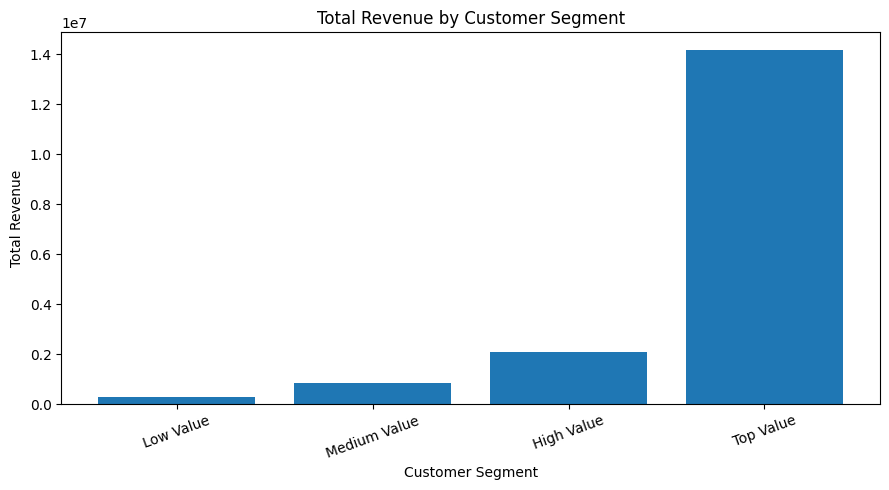

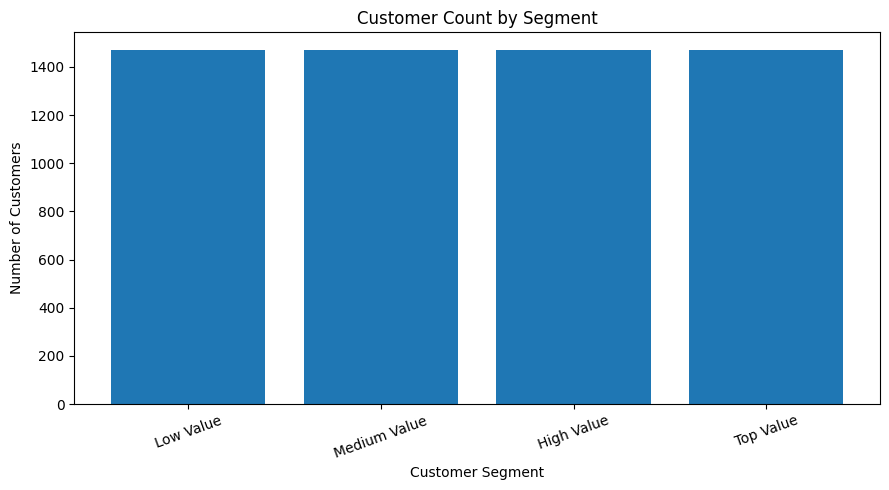

In [10]:

import matplotlib.pyplot as plt

# Revenue by customer segment
plt.figure(figsize=(9, 5))
plt.bar(
    segment_analysis["Customer_Segment"].astype(str),
    segment_analysis["Total_Revenue"]
)
plt.title("Total Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Customer distribution by segment
plt.figure(figsize=(9, 5))
plt.bar(
    segment_analysis["Customer_Segment"].astype(str),
    segment_analysis["Customer_Count"]
)
plt.title("Customer Count by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
